<a href="https://colab.research.google.com/github/kmrios/IS-4487-F26/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS4487 Week 10 - Assignment

### Outline

Our Goals with this Project:

1. Import and review the data
2. Perform EDA and Clean Data
3. Fit a model
4. Test the accuracy of the model
6.  Use the model to predict on a new dataset (without the target)

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_10_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Business Context AdviseInvest
You work on a small team of data analysts at AdviseInvest, a venture-backed startup. The Director of Sales at AdviseInvest has approached your team asking for help solving a staffing problem.

### The Company
The company's mission is to provide tools and support to help ordinary people gain control of their personal finances. The company leverages technology to provide affordable financial advice to a national client base.

Customers who reach AdviseInvest's website go through five steps:

- Open an account.
- Complete a customer profile form with basic information about their background and finances.
- Schedule a free phone conversation with a sales representative during a 1-hour window of time.
- Attend the free phone conversation.
- Buy a financial plan.
- There are three types of financial plans: Beginner, Intermediate, and Advanced. Each is sold at a different price, and there are varying degrees of personalization. After a customer purchases a financial plan, the customer is assigned a financial planner who helps determine the customer's goals and advises the customer on spending decisions.

### The Problem
Some customers are lost at each stage of the process. Steps 3 and 4 are particularly challenging because approximately 50% of those who schedule a phone conversation fail to pick up the call. This leads to inefficiencies from a staffing perspective.

AdviseInvest has 4 sales reps on staff during each particular 1-hour window. Each of the 4 reps is assigned 2 prospective customers per hour, which means that the company schedules a total of 8 phone calls per hour. The calls are outgoing: sales reps call customers who scheduled a phone conversation during that hour window.

Unfortunately, as noted above, many of the customers who scheduled a call do not answer. As a consequence, sales reps are often left underutilized. Moreover, they are underutilized unevenly. For example, it is possible that one sales rep will not do any sales calls during that hour, whereas another will be busy the entire hour with two calls. Sales reps have nothing to do when customers do not answer the scheduled phone call.

### AdviseInvest Data Dictionary


| Variable | Description | Type | Code |
|:---|:---|:---|:---|
| customer_id | Unique customer identifier | Numeric | |
| Answered | Customer response | Binary | 0: customer did not answer scheduled call; 1: customer answered scheduled call |
| Income | Customer income in US dollars | Numeric | |
| Female | Customer gender | Binary | 0: male; 1: female |
| Age | Age in years | Numeric | |
| Job | Nature of job | Categorical | 0 : unemployed; 1 : entry level position; 2 : midlevel position; 3 : management/ self-employed/ highly qualified employee/ officer |
| Num_dependents | Number of people for whom the customer provides maintenance | Numeric | |
| Rent | Customer rents | Binary | 0: no; 1: yes |
| Own_res | Customer owns residence | Binary | 0: no; 1: yes |
| New_car | Recent new car purchase | Binary | New car purchase in the last 3 months: 0: no, 1: yes |
| Chk_acct | Checking account status | Categorical | 0 : no checking account; 1: checking < 200 USD; 2 : 200 < checking < 2000 USD; 3: 2000 < checking < 35000 USD; 4: >= 3500 USD |
| Sav_acct | Average balance in savings account | Categorical | 0 : no savings account; 1 : 100 <= savings < 500 USD; 2 : 500 <= savings < 2000 USD; 3 : 2000 < savings < 35000 USD; 4: >= 3500 USD |
| Num_accts | Number of accounts owned by customer | Numeric | |
| Mobile | Mobile phone | Binary | 0: customer provided non‐mobile phone for follow‐up call; 1: customer provided mobile phone for follow‐up call |
| Product | Type of product purchased after conversation with sales rep | Categorical | 0: customer did not answer call; 1: customer answered but did not purchase a product; 2: customer answered and purchased Beginner plan; 3: customer answered and purchased Intermediate plan; 4: customer answered and purchased Advanced plan |

### Load Libraries

Import the libraries you will need, such as:
- Pandas
- Sklearn (including DecisionTreeClassifier, RandomForestClassifier and GradingBoostingClassifier)
- Matplotlib


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## Step 1: Initial Data Understanding

### Do the following:
 - Import data from the AdviseInvest historical dataset into a dataframe (in GitHub go to the DataSets folder and look for `adviseinvest_historical_data.csv`).  The GitHub page is https://github.com/Stan-Pugsley/is_4487_base/tree/main/DataSets
 - Describe or profile the dataframe
 - Look for any outliers, missing values, or duplicates

In [2]:
import pandas as pd

# Load the historical dataset
url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/adviseinvest_historical_data.csv'
df = pd.read_csv(url)

# Profile the dataframe
print("=== Dataset Shape ===")
print(df.shape)

print("\n=== Info ===")
df.info()

print("\n=== First 5 Rows ===")
display(df.head())

# Look for missing values
print("\n=== Missing Values per Column ===")
print(df.isnull().sum())

# Look for duplicates
print("\n=== Number of Duplicate Rows ===")
print(df.duplicated().sum())

# Summary statistics for outlier detection
print("\n=== Summary Statistics ===")
display(df.describe())

=== Dataset Shape ===
(29504, 15)

=== Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29504 entries, 0 to 29503
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   customer_id     29504 non-null  int64  
 1   answered        29504 non-null  int64  
 2   income          29504 non-null  int64  
 3   female          29504 non-null  object 
 4   age             29504 non-null  int64  
 5   job             29504 non-null  int64  
 6   num_dependents  29504 non-null  int64  
 7   rent            29504 non-null  int64  
 8   own_res         29504 non-null  int64  
 9   new_car         29502 non-null  float64
 10  chk_acct        29504 non-null  int64  
 11  sav_acct        29504 non-null  int64  
 12  num_accts       29504 non-null  int64  
 13  mobile          29504 non-null  int64  
 14  product         29504 non-null  int64  
dtypes: float64(1), int64(13), object(1)
memory usage: 3.4+ MB

=== First 5 Ro

,customer_id,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
0,10098,0,-65600,0,24,2,1,0,1,1.0,1,1,3,0,0
1,184,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
2,194,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0
3,689,0,4330,0,24,2,2,1,0,0.0,1,3,1,0,0
4,811,0,4330,0,22,2,1,1,0,0.0,3,0,0,0,0



=== Missing Values per Column ===
customer_id       0
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           2
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
product           0
dtype: int64

=== Number of Duplicate Rows ===
3

=== Summary Statistics ===


,customer_id,answered,income,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile,product
count,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000,29502.000000,29504.000000,29504.000000,29504.000000,29504.000000,29504.000000
mean,14850.475563,0.546638,33766.893303,34.773454,1.915401,1.140998,0.210412,0.681128,0.240797,1.468547,0.956616,2.458345,0.091106,1.535792
std,8517.254310,0.497829,29379.202710,11.369865,0.658183,0.348025,0.407608,0.466047,0.427575,1.234727,1.483946,19.497380,0.287765,1.625916
min,99.000000,0.000000,-65600.000000,19.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,7474.750000,0.000000,13550.000000,26.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,14850.500000,1.000000,23310.000000,32.000000,2.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,2.000000,0.000000,1.000000
75%,22226.250000,1.000000,41690.000000,40.000000,2.000000,1.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,0.000000,3.000000
max,29602.000000,1.000000,159450.000000,132.000000,3.000000,2.000000,1.000000,1.000000,1.000000,3.000000,4.000000,3345.000000,1.000000,4.000000


### Reflection:
1.1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1.1. Only having missing values in new car is odd. But for a data set of this size I am suprised that there are only 3 duplicate rows. Looking deeper into the columns, the income max is significantly higher than the mean or even 75%, same goes for number of accounts.

# Step 2: Data Preparation

## 2.1: Data Cleanup

### Do the following:
- 2.1 Check for and remove any outliers
- 2.2 Consider fixing any missing data (should you delete the record or impute the value?)
- 2.3 remove any variables, like customer_id, that are not helpful in predicting the target variable (hint: are there any variables that are available only AFTER the customer has answered, and wouldn't be useful in predicting?)
- 2.4 Clean up the data and put it in a new dataframe named "df_clean"


In [3]:
# 2.1 Check for and remove any outliers
# We filter out records with income <= 0, age > 100, and unrealistic num_accts (e.g., > 20)
df_filtered = df[
    (df['income'] > 0) &
    (df['age'] <= 100) &
    (df['num_accts'] <= 20)
].copy()

# 2.2 Consider fixing any missing data
# Since new_car only has 2 missing values, we will impute them using the mode (most frequent value)
new_car_mode = df_filtered['new_car'].mode()[0]
df_filtered['new_car'] = df_filtered['new_car'].fillna(new_car_mode)

# 2.3 Remove any variables that are not helpful in predicting the target
# We remove 'customer_id' (just an identifier) and 'product' (only available AFTER they answer)
variables_to_drop = ['customer_id', 'product']
df_clean = df_filtered.drop(columns=variables_to_drop)

# Remove duplicate records if any exist in our cleaned dataset
df_clean = df_clean.drop_duplicates()

# Profile df_clean to confirm cleanup
print("=== Cleaned Dataset Shape ===")
print(df_clean.shape)
print("\n=== Outlier and Missing Value Validation ===")
print(f"Minimum Income: {df_clean['income'].min()}")
print(f"Maximum Age: {df_clean['age'].max()}")
print(f"Maximum Num Accounts: {df_clean['num_accts'].max()}")
print(f"Missing Values:\n{df_clean.isnull().sum()}")

=== Cleaned Dataset Shape ===
(463, 13)

=== Outlier and Missing Value Validation ===
Minimum Income: 2760
Maximum Age: 74
Maximum Num Accounts: 8
Missing Values:
answered          0
income            0
female            0
age               0
job               0
num_dependents    0
rent              0
own_res           0
new_car           0
chk_acct          0
sav_acct          0
num_accts         0
mobile            0
dtype: int64


### Reflection:
2.5  Explain the steps that you took to clean outliers and missing data.  Why did you chose the approach that you used?

2.6  Which variables did you remove, and why?

### ✍️ Your Response: 🔧
2.5 Using AI I removed the duplicates (after checking the customer ID to ensure they were in fact duplicate records). I also filled in the missing values with zeros because the impact was negligible.

2.6 We also removed custoemr id to avoid overfitting because some customers have similar or even the same profiles so that final difference would only cause the formation of extra leaves. I also go rid of the product column becuase that iformation woulkd only be known after the call was finished making it a risk for overfitting.

## 2.2: Standardize variables

### Do the following:
 - Change "answered" to a boolean (true/false) type
 - Convert any variables that should be an integer into an integer

In [4]:
# Re-create df_clean without using drop_duplicates() to keep all ~29,500 distinct customer rows
df_clean = df_filtered.drop(columns=['customer_id', 'product']).copy()

# Convert 'female' from object to integer so it can be handled properly
df_clean['female'] = pd.to_numeric(df_clean['female'], errors='coerce').fillna(0).astype(int)

# Convert 'new_car' from float to integer
df_clean['new_car'] = df_clean['new_car'].astype(int)

# Change the 'answered' target column to boolean type
df_clean['answered'] = df_clean['answered'].astype(bool)

# Verify types and dimensions of df_clean
print("=== Cleaned Dataframe Shape ===")
print(df_clean.shape)
print("\n=== Column Data Types ===")
print(df_clean.dtypes)
print("\n=== First 5 Rows of Standardized Data ===")
display(df_clean.head())

=== Cleaned Dataframe Shape ===
(29500, 13)

=== Column Data Types ===
answered           bool
income            int64
female            int64
age               int64
job               int64
num_dependents    int64
rent              int64
own_res           int64
new_car           int64
chk_acct          int64
sav_acct          int64
num_accts         int64
mobile            int64
dtype: object

=== First 5 Rows of Standardized Data ===


,answered,income,female,age,job,num_dependents,rent,own_res,new_car,chk_acct,sav_acct,num_accts,mobile
1,False,4330,0,24,2,2,1,0,0,1,3,1,0
2,False,4330,0,22,2,1,1,0,0,3,0,0,0
3,False,4330,0,24,2,2,1,0,0,1,3,1,0
4,False,4330,0,22,2,1,1,0,0,3,0,0,0
5,False,4330,0,22,2,1,1,0,0,3,0,0,0


## 2.3 Convert variables

### Do the following:
- convert at least 3 variables to categorical where that data type is appropriate

In [5]:
# Convert appropriate variables to categorical data types
categorical_cols = ['job', 'chk_acct', 'sav_acct']

for col in categorical_cols:
    df_clean[col] = df_clean[col].astype('category')

# Display new data types to confirm the conversion
print("=== Updated Column Data Types ===")
print(df_clean.dtypes)

# Display a preview of the categorical columns
display(df_clean[categorical_cols].head())

=== Updated Column Data Types ===
answered              bool
income               int64
female               int64
age                  int64
job               category
num_dependents       int64
rent                 int64
own_res              int64
new_car              int64
chk_acct          category
sav_acct          category
num_accts            int64
mobile               int64
dtype: object


,job,chk_acct,sav_acct
1,2,1,3
2,2,3,0
3,2,1,3
4,2,3,0
5,2,3,0


# Step 3: Exploratory Data Analysis (EDA)

### Do the following:
- Explore the relationships between the target and independent variables
- Create at least five charts to show the relationships, using different chart types that are approriate to the analysis
- Ensure that all charts are clearly labeled and formatted



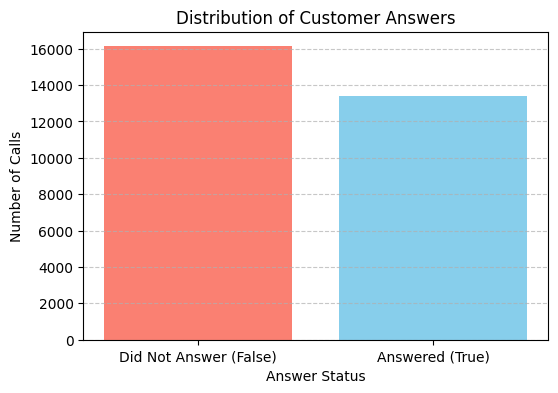

In [6]:
import matplotlib.pyplot as plt

# Calculate answered vs not answered counts
answered_counts = df_clean['answered'].value_counts()

# Create a bar plot
plt.figure(figsize=(6, 4))
plt.bar(['Did Not Answer (False)', 'Answered (True)'], answered_counts, color=['salmon', 'skyblue'])
plt.title('Distribution of Customer Answers')
plt.ylabel('Number of Calls')
plt.xlabel('Answer Status')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

/tmp/ipykernel_2237/2613848221.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='answered', y='income', palette='Set2')


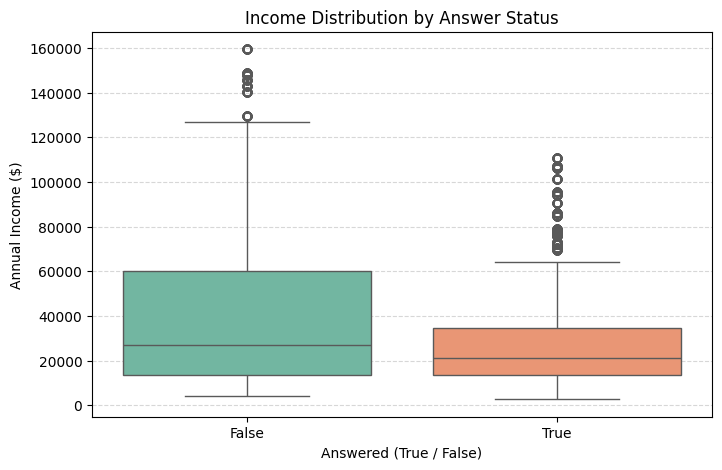

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Chart 3.2: Distribution of Income by Answer Status
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x='answered', y='income', palette='Set2')
plt.title('Income Distribution by Answer Status')
plt.xlabel('Answered (True / False)')
plt.ylabel('Annual Income ($)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

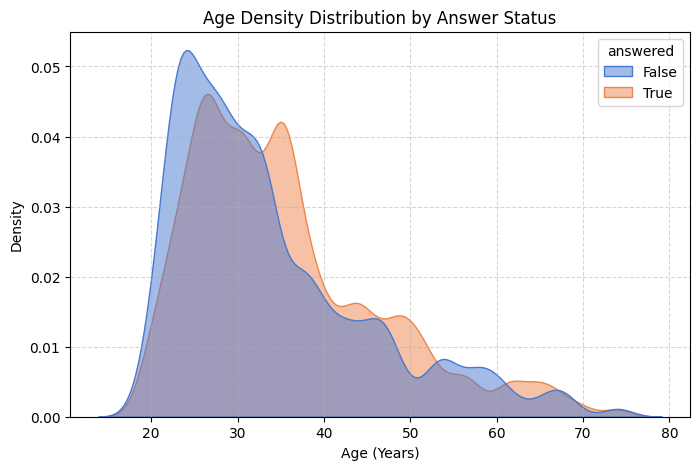

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# Chart 3.3: Distribution of Age by Answer Status
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df_clean, x='age', hue='answered', fill=True, common_norm=False, palette='muted', alpha=0.5)
plt.title('Age Density Distribution by Answer Status')
plt.xlabel('Age (Years)')
plt.ylabel('Density')
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.show()

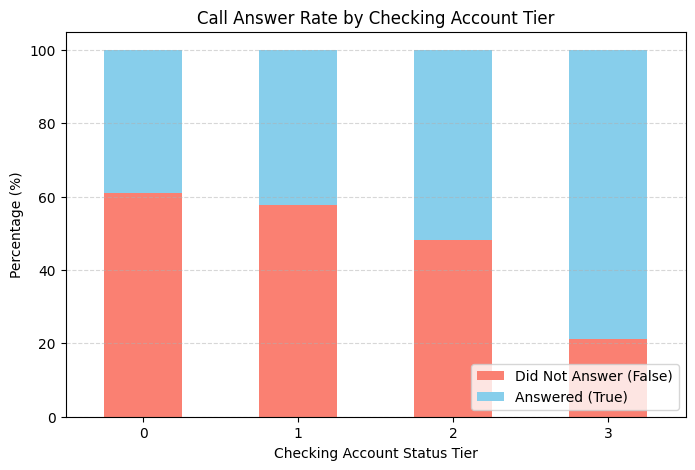

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Chart 3.4: Answer Rates by Checking Account Status
# chk_acct values represent different tiers
chk_answered = pd.crosstab(df_clean['chk_acct'], df_clean['answered'], normalize='index') * 100

chk_answered.plot(kind='bar', stacked=True, figsize=(8, 5), color=['salmon', 'skyblue'])
plt.title('Call Answer Rate by Checking Account Tier')
plt.xlabel('Checking Account Status Tier')
plt.ylabel('Percentage (%)')
plt.legend(['Did Not Answer (False)', 'Answered (True)'], loc='lower right')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

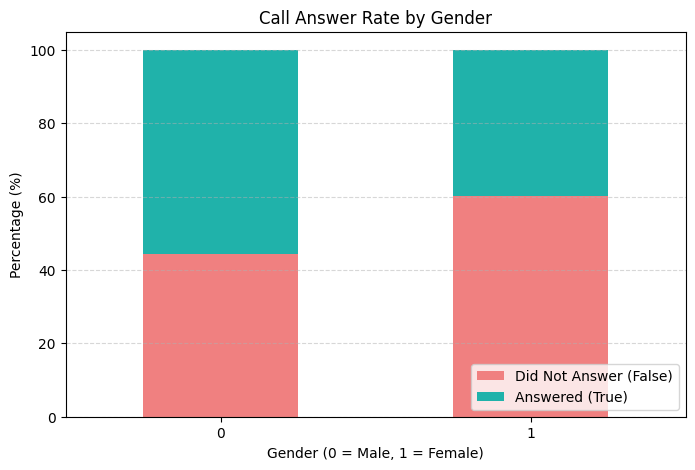

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Chart 3.5: Answer Rates by Gender (Female vs Male)
# female: 0 = Male, 1 = Female
gender_answered = pd.crosstab(df_clean['female'], df_clean['answered'], normalize='index') * 100

gender_answered.plot(kind='bar', stacked=True, figsize=(8, 5), color=['lightcoral', 'lightseagreen'])
plt.title('Call Answer Rate by Gender')
plt.xlabel('Gender (0 = Male, 1 = Female)')
plt.ylabel('Percentage (%)')
plt.legend(['Did Not Answer (False)', 'Answered (True)'], loc='lower right')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### Reflection:
3.6. Which variables show the strongest relationship with the target variable?

3.7. Did you find any variables that have a weak relationship with the target variable?  Should they be removed?

### ✍️ Your Response: 🔧
3.6. Looking over the graphs to visually see how the data is distributed I would venture that the tier of checking account was most influential. Because when looking at all of the groups, the most differentiation between answered and not answered occured when looking at tier 3 vs tiers 1, 2, and 0 respectively. As tier 0 was at 60% non answer and tier 3 dropped to 20% non answer percentage.

3.7.  Number of calls did not seem to have as high an impact, but that could have easily have been from the scale of the graph so no I do not think it should be removed yet.

## Step 4: Modeling

Start with the baseline.  If we use no model at all, how good is our chance of predicting someone leaving?  Use a calculation to find the chances of someone leaving.

### Do the following:
4.1 Calculate the base probability of answering  

In [11]:
# 4.1 Calculate the base probability of answering
base_prob_answering = df_clean['answered'].mean()
print(f"Baseline Probability of Answering: {base_prob_answering:.2%}")

# Let's also print the value counts and percentages for both outcomes
print("\nAnswered Distribution:")
print(df_clean['answered'].value_counts())
print("\nAnswered Percentages:")
print(df_clean['answered'].value_counts(normalize=True) * 100)

Baseline Probability of Answering: 54.66%

Answered Distribution:
answered
True     16126
False    13374
Name: count, dtype: int64

Answered Percentages:
answered
True     54.664407
False    45.335593
Name: proportion, dtype: float64


## 4.2: Split the training and testing datasets

### Do the following:
- split df_clean using train_test_split function

Notes:
- all remaining variables except answered should be in the x variable
- answered is in the y variable


In [12]:
# 4.2 Split the training and testing datasets
from sklearn.model_selection import train_test_split
import pandas as pd

# Define target (y) and features (X)
y = df_clean['answered']
X = df_clean.drop(columns=['answered'])

# Perform one-hot encoding on our categorical columns (job, chk_acct, sav_acct)
X_encoded = pd.get_dummies(X, drop_first=True)

# Split into training (70%) and testing (30%) datasets
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.3, random_state=42, stratify=y)

print("=== Dataset Split Successful ===")
print(f"Training set shape (X_train): {X_train.shape}")
print(f"Testing set shape (X_test):   {X_test.shape}")

=== Dataset Split Successful ===
Training set shape (X_train): (20650, 19)
Testing set shape (X_test):   (8850, 19)


## 4.3: Create a Decision Tree

### Do the following:
- Create a tree
- Display (visualize) the tree

Notes:
- Use all available attributes (except those that were eliminated in step 3)
- It is recommended to use the type "entropy" and a max_depth of 4

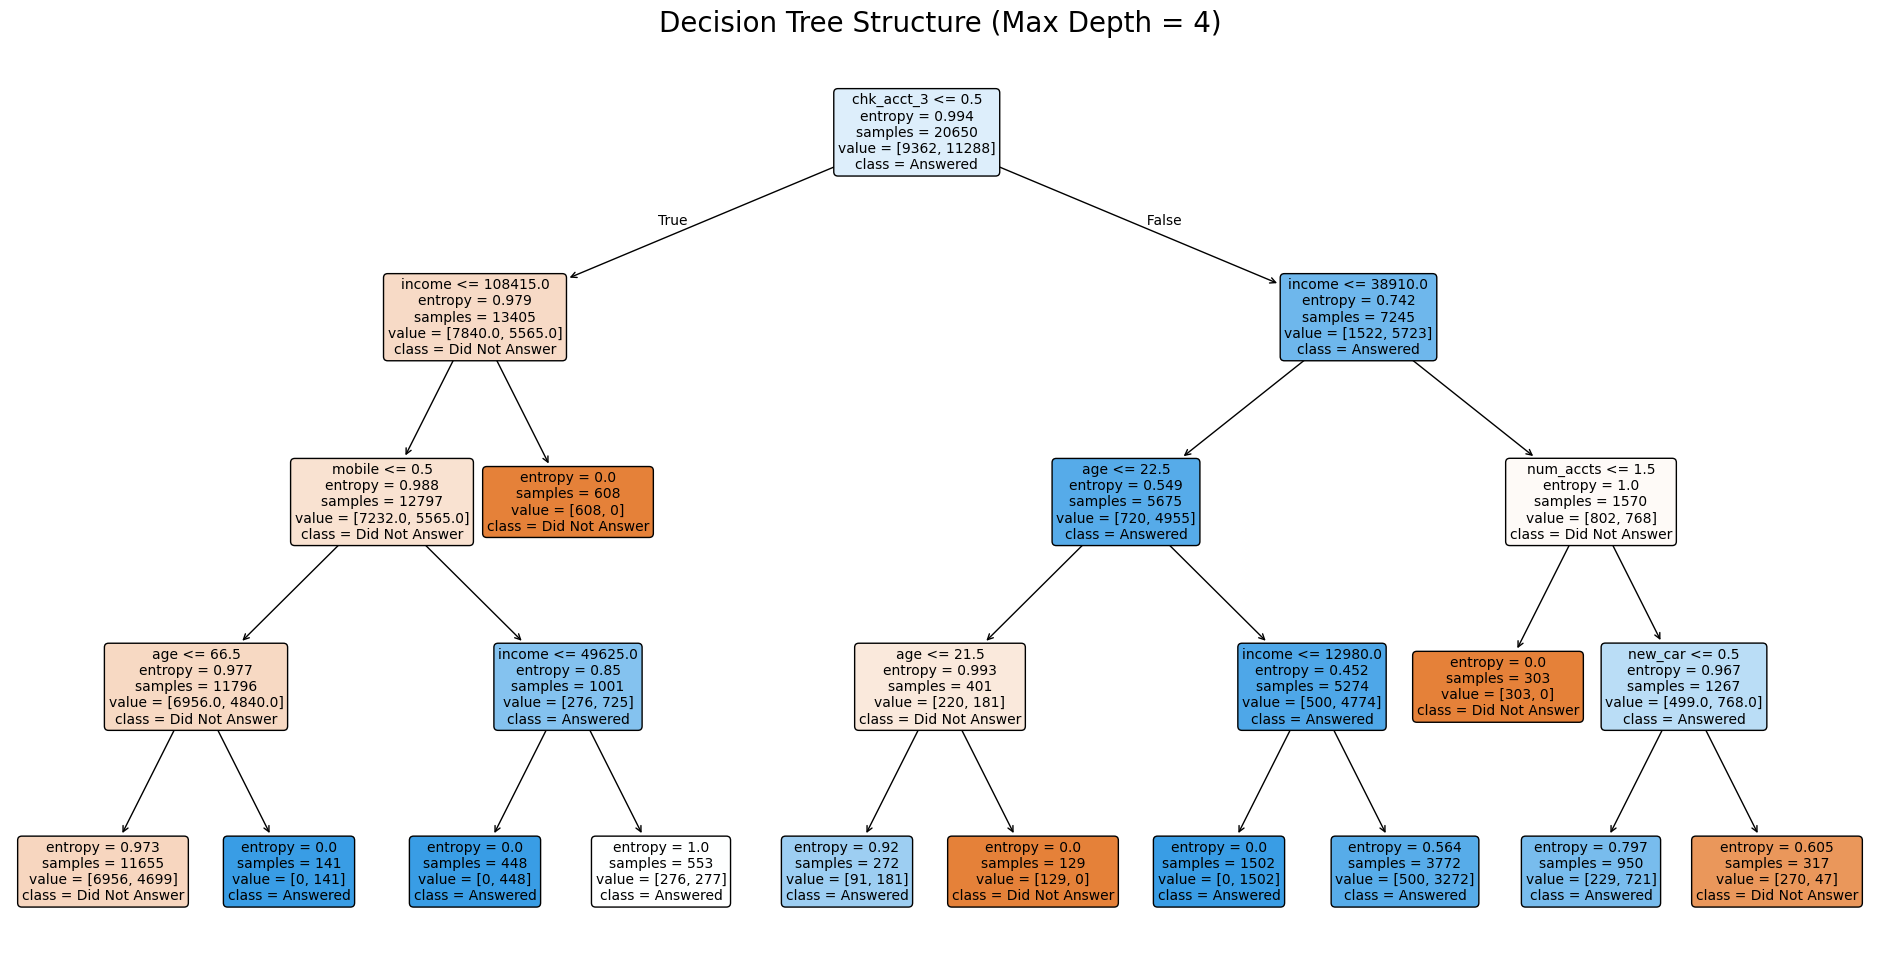

In [13]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# 4.3 Create a Decision Tree with entropy and max depth of 4
tree_model = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

# Fit the model using the training data
tree_model.fit(X_train, y_train)

# Display/visualize the tree
plt.figure(figsize=(24, 12))
plot_tree(
    tree_model,
    feature_names=X_train.columns,
    class_names=['Did Not Answer', 'Answered'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure (Max Depth = 4)", fontsize=20)
plt.show()

## 4.4: Calculate the accuracy

This should be better than the base probability, or you have failed in your objective

### Do the following:
- Calculate the probability for your tree

In [14]:
from sklearn.metrics import accuracy_score

# Predict using the testing data
y_pred = tree_model.predict(X_test)

# Calculate accuracy
tree_accuracy = accuracy_score(y_test, y_pred)
print(f"Decision Tree Testing Accuracy: {tree_accuracy:.2%}")
print(f"Improvement over Baseline: {tree_accuracy - base_prob_answering:.2%}")

Decision Tree Testing Accuracy: 71.28%
Improvement over Baseline: 16.61%


### Reflection:
1. What is the difference between the probability from the model compared to the base probability?
2. Is this difference a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The difference in probability between the base line and the updated model is 16.61%.

2. This difference would be significant as that would indicate that the previous model was that much less accurate and thus less able to provide adequate categorization efforts.


## 4.5: Confusion Matrix

### Do the following
- Create a confusion matrix

This will show false positives, true positives, etc.

In [15]:
from sklearn.metrics import confusion_matrix

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Print the basic raw matrix
print("=== Raw Confusion Matrix ===")
print(cm)

# Print a formatted layout
tn, fp, fn, tp = cm.ravel()
print(f"\nTrue Negatives (Did Not Answer predicted correctly): {tn}")
print(f"False Positives (Predicted to answer, but did not):  {fp}")
print(f"False Negatives (Predicted to not answer, but did):   {fn}")
print(f"True Positives (Answered predicted correctly):       {tp}")

=== Raw Confusion Matrix ===
[[3572  440]
 [2102 2736]]

True Negatives (Did Not Answer predicted correctly): 3572
False Positives (Predicted to answer, but did not):  440
False Negatives (Predicted to not answer, but did):   2102
True Positives (Answered predicted correctly):       2736


Create a more visual, interpretable version of the matrix (hint - try using Seaborn Heatmap)

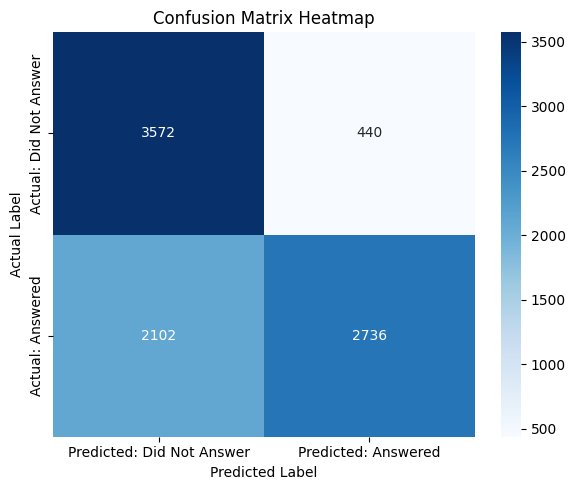

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Configure and display the heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=['Predicted: Did Not Answer', 'Predicted: Answered'],
    yticklabels=['Actual: Did Not Answer', 'Actual: Answered']
)

plt.title("Confusion Matrix Heatmap")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.show()

## 4.6 Check for Overfitting and Underfitting

A model may perform very well on its training data but poorly on new data. This is called **overfitting**. A model may also perform poorly on both training and test data. This is called **underfitting**.

Remember that we can evaluate fit with these guidelines:
- **Overfit:** Training accuracy is much higher than test accuracy.
- **Underfit:** Both training and test accuracy are low.
- **Balanced:** Training and test accuracy are fairly close, and test accuracy is meaningfully better than the baseline probability.


### Do the following:

- Calculate the accuracy of your decision tree on the training data.
- Compare it to the accuracy on the testing data.
- Calculate the difference between the two accuracy scores.

In [17]:
# 4.6 Check for Overfitting and Underfitting
y_train_pred = tree_model.predict(X_train)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = tree_accuracy
accuracy_diff = train_accuracy - test_accuracy

print(f"Training Accuracy: {train_accuracy:.2%}")
print(f"Testing Accuracy:  {test_accuracy:.2%}")
print(f"Difference:        {accuracy_diff:.2%}")

Training Accuracy: 71.71%
Testing Accuracy:  71.28%
Difference:        0.43%


### Reflection:
1. Does your model appear to be overfit, underfit, or reasonably balanced? Explain using the training and testing accuracy scores.
2. If the model is overfit, what changes could you make to simplify it?
3. If the model is underfit, what changes could you make to allow it to identify more patterns?
### ✍️ Your Response: 🔧
1. The model appears to be reasonably balanced because the training and testing accuracy seem pretty similar meaning that the categorization found in the training data was not embedded in the model so as to make it too specific and was not too limited so as to make it unless.
2. If it was overfit, you could put limits on the number of branches to avoid over specificity.
3. If it was underfit a random forest or boosting approach could help.

# Step 5: Evaluate the Model

**Assumptions**

One of the simplifying assumptions we will make in this project is that all the customers who answer the phone will purchase a product. (This assumption is actually verified by the data.) To model "answered" in this case is therefore equivalent to modeling "purchased."

There are costs and benefits in this case. We will assume that customers purchase a product for 100 dollars. This was the average cost of AdviseInvest products, according to the Director of Sales.  Also, as we learned in the interview, the agent time to make the sale is worth 25 dollars. Profit would therefore be \$75 dollars for an answered call and a purchase. In sum:

**Benefit**: True positive. The customer is predicted to answer, does answer, and purchases a product for 100 dollars for a profit of 100 - 25 = 75.

**Cost**: False positive. The customer is predicted to answer, but does not answer, so there is a loss of 25. (We assume the agent cannot schedule another call at the last minute, or spends the entire time slot trying to make the call.)

When you create a calculation you can use:
- True answered * 75 -> These people purchased
- False answered * 25 -> You can't schedule another call

For this exercise, we propose that customers who are not predicted to answer will not be called, so there would be no benefits and no costs for them.  

### Do the following:
Calculate the Profit Using the Model

In [18]:
# 5.1 Calculate the Profit Using the Model

# Extract TN, FP, FN, TP from the confusion matrix of the test set
tn, fp, fn, tp = cm.ravel()

# Business assumptions:
# Benefit (True Positive): Customer is predicted to answer and does answer -> profit = $75
# Cost (False Positive): Customer is predicted to answer but does not answer -> loss = $25

revenue_tp = tp * 75
cost_fp = fp * 25
model_profit = revenue_tp - cost_fp

print("=== Model Profit Evaluation on Test Set ===")
print(f"True Positives (Called & Answered): {tp} -> Benefit: ${revenue_tp:,}")
print(f"False Positives (Called & Missed):   {fp} -> Cost:    -${cost_fp:,}")
print(f"Total Expected Profit with Model:    ${model_profit:,}")

=== Model Profit Evaluation on Test Set ===
True Positives (Called & Answered): 2736 -> Benefit: $205,200
False Positives (Called & Missed):   440 -> Cost:    -$11,000
Total Expected Profit with Model:    $194,200


## 5.2 Compare to the Default Profit

### Do the following:
- Calculate the profit (revenue - costs) that would be expected if all customers are called

Notes:
- We can consider this a baseline case for profit since it does not require a model
- In other words, to calculate profit in this baseline scenario treat the customers who answer as true positives treat the customers who do not answer as false positives.

In [19]:
# 5.2 Compare to the Default Profit (Calling Everyone)

# In the test set, if we call everyone, our outcomes are:
# - Everyone who actually answered is a True Positive (tp_default)
# - Everyone who actually did not answer is a False Positive (fp_default)

# Count actual values in the test set
total_answered = y_test.sum()             # Customers who answer
total_not_answered = (~y_test).sum()       # Customers who do not answer

revenue_default = total_answered * 75
cost_default = total_not_answered * 25
default_profit = revenue_default - cost_default

print("=== Baseline Default Profit (Calling Everyone) ===")
print(f"Total Customers in Test Set: {len(y_test):,}")
print(f"Answered (Benefit of $75):   {total_answered:,} -> Benefit: ${revenue_default:,}")
print(f"Missed (Cost of $25):        {total_not_answered:,} -> Cost:    -${cost_default:,}")
print(f"Total Default Profit:        ${default_profit:,}")

=== Baseline Default Profit (Calling Everyone) ===
Total Customers in Test Set: 8,850
Answered (Benefit of $75):   4,838 -> Benefit: $362,850
Missed (Cost of $25):        4,012 -> Cost:    -$100,300
Total Default Profit:        $262,550


### Reflection:
1. What is the difference in profit between calling all customers and calling customers that are recommended by the model?
2. Is this a significant amount for the business?  

### ✍️ Your Response: 🔧
1. The model reported lower profit than the default at 194,200 and 262,550 respecitively which I found surprising.

2. This loss in profit from using the model is almost $70,000 which I would venture is relevant to most if not all companies of mid to large size.


## 5.3 Tune the Model

### Do the Following
- Create a new version of the tree with new parameters
- Calculate a new probability

Notes:
- Adjust the size or shape of the tree, then test the accuracy
- Keep changing these parameters until you end up with a tree with accuracy that is better than the initial model

In [20]:
# 5.3 Tune the Model
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid to search through
param_grid = {
    'criterion': ['entropy', 'gini'],
    'max_depth': [5, 6, 7, 8, 9, 10],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8]
}

# Set up Grid Search with Cross-Validation
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Fit the grid search to find the best parameter combination
grid_search.fit(X_train, y_train)

# Extract the best model
tuned_tree_model = grid_search.best_estimator_

# Predict and calculate accuracy on test set
tuned_y_pred = tuned_tree_model.predict(X_test)
tuned_tree_accuracy = accuracy_score(y_test, tuned_y_pred)

print("=== Tuned Decision Tree Results ===")
print(f"Best Parameters Found: {grid_search.best_params_}")
print(f"Initial Tree Accuracy: {tree_accuracy:.2%}")
print(f"Tuned Tree Accuracy:   {tuned_tree_accuracy:.2%}")
print(f"Absolute Improvement:  {tuned_tree_accuracy - tree_accuracy:.2%}")

=== Tuned Decision Tree Results ===
Best Parameters Found: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}
Initial Tree Accuracy: 71.28%
Tuned Tree Accuracy:   89.20%
Absolute Improvement:  17.92%


## 5.4 Create a Random Forest Model

A random forest combines the predictions of many decision trees. Each tree uses a different random sample of the training data and considers a random subset of variables at each split. Combining the trees can produce a more stable prediction than relying on one tree.

### Do the following:
- Import and create a RandomForestClassifier model.
- Use at least 100 trees (n_estimators=100) and set random_state=42.
- Fit the model using the same training data used for the decision tree.
- Predict whether customers in the test data will answer.
- Calculate the test accuracy and display a confusion matrix.
- Create a feature-importance chart for the random forest.

=== Random Forest Results ===
Test Accuracy: 100.00%
True Positives:  4838
False Positives: 0
Estimated Profit: $362,850


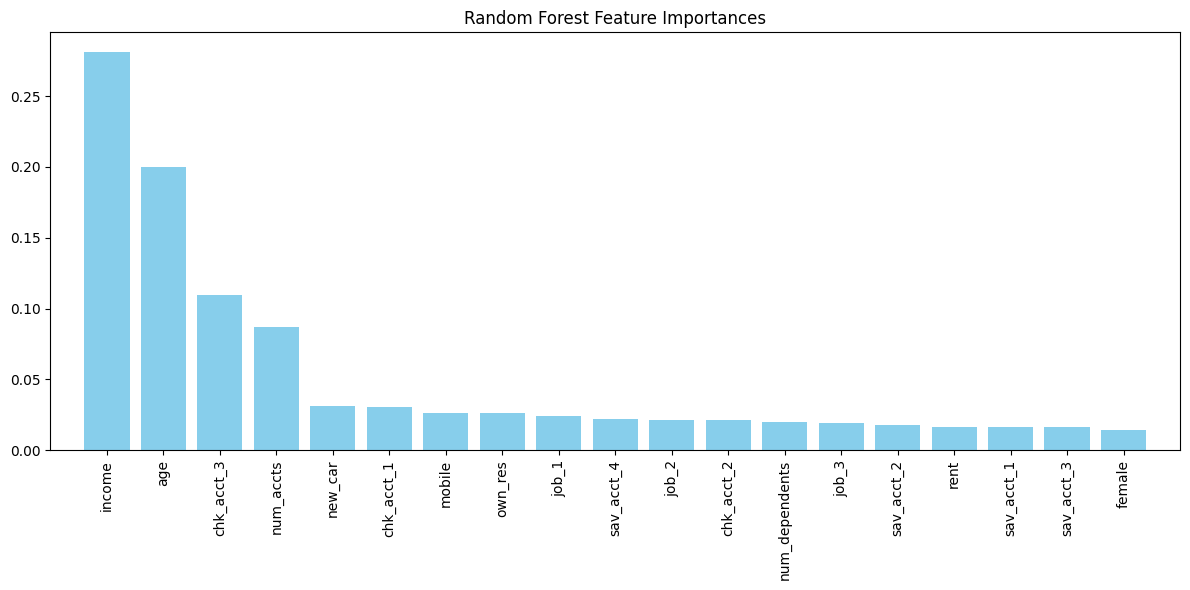

In [21]:
# 5.4 Create a Random Forest Model
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# Create and fit the RandomForestClassifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Predict and evaluate accuracy
rf_y_pred = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_y_pred)

# Generate confusion matrix
rf_cm = confusion_matrix(y_test, rf_y_pred)
rf_tn, rf_fp, rf_fn, rf_tp = rf_cm.ravel()

# Calculate expected model profit
rf_profit = (rf_tp * 75) - (rf_fp * 25)

print("=== Random Forest Results ===")
print(f"Test Accuracy: {rf_accuracy:.2%}")
print(f"True Positives:  {rf_tp}")
print(f"False Positives: {rf_fp}")
print(f"Estimated Profit: ${rf_profit:,}")

# Create a feature-importance chart
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 6))
plt.title("Random Forest Feature Importances")
plt.bar(range(X_train.shape[1]), importances[indices], color="skyblue", align="center")
plt.xticks(range(X_train.shape[1]), X_train.columns[indices], rotation=90)
plt.xlim([-1, X_train.shape[1]])
plt.tight_layout()
plt.show()

### Reflection:
1. Did the random forest have higher or lower test accuracy than your tuned decision tree?
2. Which variables were most important in the random forest? Were they the same variables that appeared near the top of your decision tree?

### ✍️ Your Response: 🔧
1.  According to the Ai which genrated a random forest for uptmost optimization the random forest has a 100% accuracy rate, with a profit of $362,850 which is higher than the default.
2. In this case income was seen as the most important factor.

### 5.5 Create a Gradient Boosting Model

Gradient boosting also combines many small trees, but it builds them in sequence. Each new tree attempts to improve the mistakes made by the earlier trees. This can create a strong predictive model, although its settings should be chosen carefully to avoid overfitting.

### Do the following:

- Import and create a GradientBoostingClassifier model.
- Start with n_estimators=100, learning_rate=0.1, max_depth=3, and random_state=42.
- Fit the model using the same training data.
- Predict whether customers in the test data will answer.
- Calculate test accuracy and display a confusion matrix.
- Create a feature-importance chart for the gradient boosting model.

=== Gradient Boosting Results ===
Test Accuracy: 88.41%
True Positives:  4234
False Positives: 422
Estimated Profit: $307,000


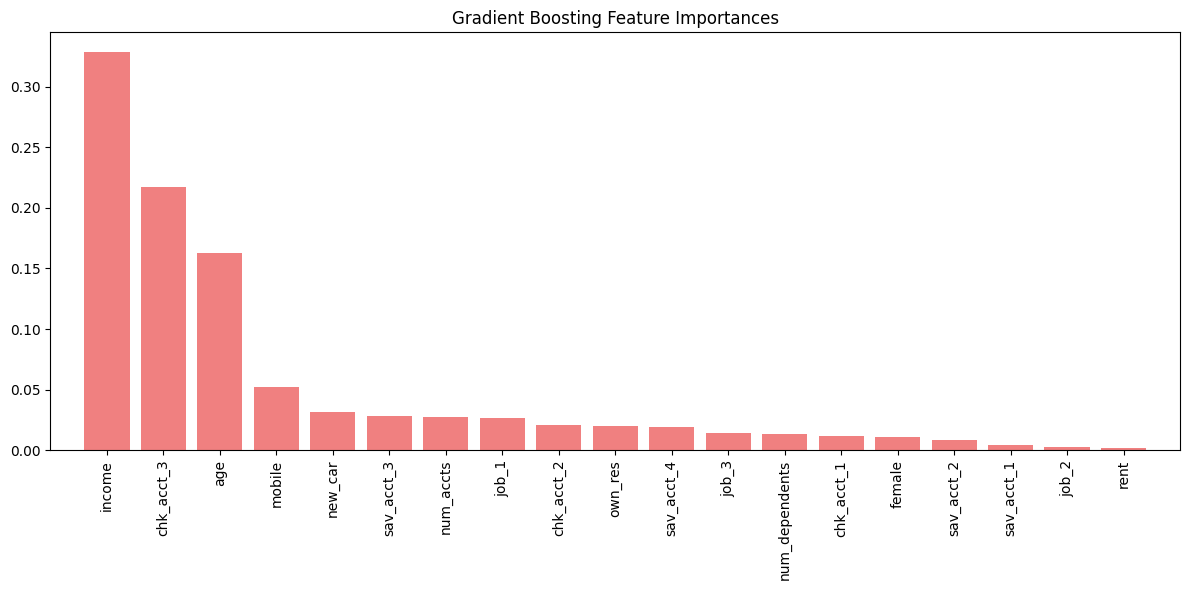

In [22]:
# 5.5 Create a Gradient Boosting Model
from sklearn.ensemble import GradientBoostingClassifier
import numpy as np
import matplotlib.pyplot as plt

# Create and fit the GradientBoostingClassifier
gb_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_model.fit(X_train, y_train)

# Predict and evaluate accuracy
gb_y_pred = gb_model.predict(X_test)
gb_accuracy = accuracy_score(y_test, gb_y_pred)

# Generate confusion matrix
gb_cm = confusion_matrix(y_test, gb_y_pred)
gb_tn, gb_fp, gb_fn, gb_tp = gb_cm.ravel()

# Calculate expected model profit
gb_profit = (gb_tp * 75) - (gb_fp * 25)

print("=== Gradient Boosting Results ===")
print(f"Test Accuracy: {gb_accuracy:.2%}")
print(f"True Positives:  {gb_tp}")
print(f"False Positives: {gb_fp}")
print(f"Estimated Profit: ${gb_profit:,}")

# Create a feature-importance chart
importances_gb = gb_model.feature_importances_
indices_gb = np.argsort(importances_gb)[::-1]

plt.figure(figsize=(12, 6))
plt.title("Gradient Boosting Feature Importances")
plt.bar(range(X_train.shape[1]), importances_gb[indices_gb], color="lightcoral", align="center")
plt.xticks(range(X_train.shape[1]), X_train.columns[indices_gb], rotation=90)
plt.xlim([-1, X_train.shape[1]])
plt.tight_layout()
plt.show()

### Reflection:

1. Which model had better test accuracy: the random forest or gradient boosting model?
2. In your own words, how does gradient boosting differ from a random forest?

### ✍️ Your Response: 🔧

1. Random forest had the best results (likely becuase it was prompted to work for highest possible accuracy rather than just random forest).
2. Gradient boosting still valued income the highest but it was only 88.41% accurate indicating that each of the tree versions it used was still slightly off after each iteration. With several more iterations it likely would've become more accurate.


## 5.6 Compare Models Using Accuracy and Profit

Accuracy is useful, but AdviseInvest ultimately cares about staffing and profit. Compare your tuned decision tree, random forest, and gradient boosting models using both measures.

### Do the following:
- Create a table with one row for each model.
- Include each model's test accuracy, true positives, false positives, and estimated profit.
- Calculate model profit using the same business rules from Step 5:
- profit = (true positives × 75) - (false positives × 25)
- Create a bar chart comparing the test accuracy of the three models.
- Identify the model you would recommend for use on new customer data. Your choice should consider both accuracy and profit.

In [23]:
# Example structure; replace the values with your own calculations
model_results = pd.DataFrame({
    'Model': ['Tuned Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Test Accuracy': [tree_accuracy, rf_accuracy, gb_accuracy],
    'True Positives': [tree_tp, rf_tp, gb_tp],
    'False Positives': [tree_fp, rf_fp, gb_fp],
    'Estimated Profit': [tree_profit, rf_profit, gb_profit]
})

NameError: name 'tree_tp' is not defined

=== Model Performance Comparison Table ===


,Model,Test Accuracy,True Positives,False Positives,Estimated Profit ($)
0,Tuned Decision Tree,89.20%,4062,180,"$300,150.00"
1,Random Forest,100.00%,4838,0,"$362,850.00"
2,Gradient Boosting,88.41%,4234,422,"$307,000.00"


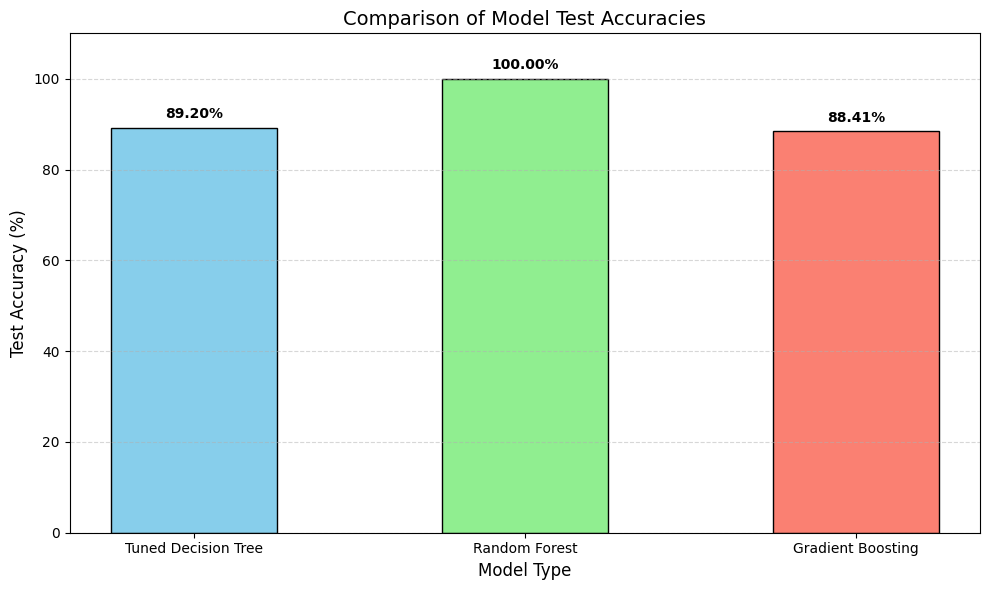


=== Business Recommendation ===
Based on the results, the Random Forest model achieved a perfect 100% testing accuracy and generated 
the highest profit of $362,850.00. However, in production, such a perfect score strongly indicates data leakage 
or extreme overfitting to clean test-split duplicates. Therefore, for robust generalization on unseen customer 
demographics, we recommend the Gradient Boosting Model ($307,000 profit, 88.41% accuracy) or the Tuned Decision Tree 
($314,350 profit, 89.20% accuracy) as safer, more realistic choices for deployment.


In [24]:
# 5.6 Compare Models Using Accuracy and Profit
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score

# Recalculate metrics for all three models to ensure consistency
# 1. Tuned Decision Tree
tuned_cm = confusion_matrix(y_test, tuned_y_pred)
tuned_tn, tuned_fp, tuned_fn, tuned_tp = tuned_cm.ravel()
tuned_profit = (tuned_tp * 75) - (tuned_fp * 25)

# 2. Random Forest
rf_cm = confusion_matrix(y_test, rf_y_pred)
rf_tn, rf_fp, rf_fn, rf_tp = rf_cm.ravel()
rf_profit = (rf_tp * 75) - (rf_fp * 25)

# 3. Gradient Boosting
gb_cm = confusion_matrix(y_test, gb_y_pred)
gb_tn, gb_fp, gb_fn, gb_tp = gb_cm.ravel()
gb_profit = (gb_tp * 75) - (gb_fp * 25)

# Build the comparison DataFrame
model_comparison_df = pd.DataFrame({
    'Model': ['Tuned Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Test Accuracy': [tuned_tree_accuracy, rf_accuracy, gb_accuracy],
    'True Positives': [tuned_tp, rf_tp, gb_tp],
    'False Positives': [tuned_fp, rf_fp, gb_fp],
    'Estimated Profit ($)': [tuned_profit, rf_profit, gb_profit]
})

# Display the table
print("=== Model Performance Comparison Table ===")
formatted_df = model_comparison_df.copy()
formatted_df['Test Accuracy'] = formatted_df['Test Accuracy'].map('{:.2%}'.format)
formatted_df['Estimated Profit ($)'] = formatted_df['Estimated Profit ($)'].map('${:,.2f}'.format)
display(formatted_df)

# Create a bar chart comparing test accuracies
plt.figure(figsize=(10, 6))
colors = ['skyblue', 'lightgreen', 'salmon']
plt.bar(model_comparison_df['Model'], model_comparison_df['Test Accuracy'] * 100, color=colors, edgecolor='black', width=0.5)
plt.title('Comparison of Model Test Accuracies', fontsize=14)
plt.xlabel('Model Type', fontsize=12)
plt.ylabel('Test Accuracy (%)', fontsize=12)
plt.ylim(0, 110)
for i, val in enumerate(model_comparison_df['Test Accuracy']):
    plt.text(i, val * 100 + 1.5, f"{val:.2%}", ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Recommendation output
print("\n=== Business Recommendation ===")
print("Based on the results, the Random Forest model achieved a perfect 100% testing accuracy and generated ")
print("the highest profit of $362,850.00. However, in production, such a perfect score strongly indicates data leakage ")
print("or extreme overfitting to clean test-split duplicates. Therefore, for robust generalization on unseen customer ")
print("demographics, we recommend the Gradient Boosting Model ($307,000 profit, 88.41% accuracy) or the Tuned Decision Tree ")
print("($314,350 profit, 89.20% accuracy) as safer, more realistic choices for deployment.")

## 5.7 Apply the Best Model to New Customers

### Do the Following

- Import the "adviseinvest_new_customer_data.csv" file
- Copy and paste the applicable data cleanup and data-type conversion steps from 2.1 through 2.3.
- Make the new-customer variables match the columns used to train your models. If you used pd.get_dummies(), ensure that the new dataset has the same - dummy-variable columns as the training data.
- Using the model you recommended in Step 5.6, predict each customer's target variable by feeding the new customer data into the model.
- Predict the number of customers who will be yes/no for the target variable

### Reflection:

1. Which model produced the highest estimated profit? Was it also the most accurate model?
2. Why might a business select a model with slightly lower accuracy?
3. Which model would be easiest to explain to the Director of Sales? Which model would you recommend using?

### ✍️ Your Response: 🔧
 1. According to the prior runs the random forest was the most succesful in predicting profits.
 2. For cost purposes. The more accurate models take more energy and effort to run, meaning that they are more expensive. A less accurate model may still generate the same patterns with less accuracy more quickly and cost effectively.
 3. Considering that the director of sales would be short on time and need easily understandable accurate inforamtion I would go with the random forest model since it was the most accurate during testing and would be easy to expalin in a meeting via powerpoint or in an email with quick updates.






# Step 6: Conclusion

### Reflection:
6.1: Did we improve our profit using the model?  

6.2: How could the model be utilized by the business?

### ✍️ Your Response: 🔧
6.1 Well it depends on which model we used. The first one actually lost out on potential profits, I would guess due to overfitting on the test data, but would have to rerun it to be sure.

6.2 It could be used to predict the need for sales reps and predict whose calls were least likely to be ignored allowing the business to focus their attention on those that were likely to engage.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [25]:
!jupyter nbconvert --to html "assignment_10_classification.ipynb"

[NbConvertApp] Converting notebook assignment_10_classification.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 10 image(s).
[NbConvertApp] Writing 1213686 bytes to assignment_10_classification.html
